# Indonesian Data Job Market Intelligence
## Pipeline Transformasi, Pembersihan, dan Rekayasa Fitur Data Lowongan Kerja: JobStreet Indonesia

Notebook ini memproses data mentah (*raw data*) lowongan kerja bidang data dari portal **JobStreet Indonesia (SEEK Platform)** menjadi dataset analitik yang terstandarisasi, bersih, dan tervalidasi. 

### Alur Rekayasa Fitur & Transformasi:
1. **Audit & Deduplikasi:** Pengecekan duplikasi URL dan integrasi snapshot mentah terbaru.
2. **Normalisasi Lokasi Presisi:** Memisahkan teks lokasi menjadi `city`, `province`, dan `work_mode` (On-site, Hybrid, Remote) dengan penanganan khusus wilayah Jabodetabek & kota regional.
3. **Standarisasi Gaji Multi-Format:** Ekstraksi rentang gaji numerik, konversi gaji per jam (USD) ke bulanan (IDR), dan penentuan `salary_median`.
4. **Pendidikan Formal:** Ekstraksi tingkat kualifikasi minimum (`education_requirement`) dari teks deskripsi lowongan.
5. **Tingkat Pengalaman Kategorikal:** Penentuan level pengalaman terstandardisasi (`experience_level`: *Entry-Level, Junior / Associate, Mid-Level, Senior-Level*).
6. **Taksonomi Profesi Data & Filter Non-Data:** Klasifikasi peran (`role_group` & `role_standard`) dan eliminasi lowongan non-data seperti infrastruktur fisik (*Data Center Facility*, *Site Engineer*, dsb.).
7. **Ekstraksi Keahlian (Skills & Tools):** Pemetaan kamus keahlian teknis (*Programming Languages, BI & Visualization, Databases, Cloud & Big Data, Data Science/ML*).
8. **Eksplorasi Data Awal (EDA BR-01 s/d BR-06):** Visualisasi proporsi profesi, top skill, tingkat pengalaman, pendidikan, sebaran gaji, dan fleksibilitas kerja.
9. **Analisis Transparansi & Profil Nilai Tidak Disebutkan:** Audit keterisian informasi pasar kerja.

### Sel 1: Inisialisasi Dependensi & Library Analisis Data

In [1]:
import os
import sys
import glob
import re
from pathlib import Path
from datetime import datetime

# Konsistensi encoding terminal Windows
if sys.platform == "win32" and hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Path Proyek
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent.parent if NOTEBOOK_DIR.name == "transform_data" else NOTEBOOK_DIR
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"[{datetime.now().strftime('%Y-%m-%d %H:%M:%S')}] Dependensi dan direktori siap:")
print(f"  - Raw Dir       : {RAW_DATA_DIR}")
print(f"  - Processed Dir : {PROCESSED_DATA_DIR}")
print(f"  - Figures Dir   : {FIGURES_DIR}")

[2026-10-31 23:27:01] Dependensi dan direktori siap:
  - Raw Dir       : C:\Users\Victus 16\data-project\analisi_loker_data_indonesia\data\raw
  - Processed Dir : C:\Users\Victus 16\data-project\analisi_loker_data_indonesia\data\processed
  - Figures Dir   : C:\Users\Victus 16\data-project\analisi_loker_data_indonesia\outputs\figures


### Sel 2: Pemuatan Data Mentah JobStreet Terbaru

In [2]:
# Temukan snapshot data mentah JobStreet terbaru
raw_files = sorted(RAW_DATA_DIR.glob("jobstreet_raw_*.csv"))
if not raw_files:
    raise FileNotFoundError(f"Tidak ada file snapshot jobstreet_raw_*.csv di {RAW_DATA_DIR}")

latest_raw_file = raw_files[-1]
print(f"Memuat snapshot mentah terbaru: {latest_raw_file.name}")

df_raw = pd.read_csv(latest_raw_file)
print(f"Total baris mentah dimuat: {len(df_raw)} baris, {len(df_raw.columns)} kolom.")
display(df_raw.head(3))

Memuat snapshot mentah terbaru: jobstreet_raw_20261031_230119.csv
Total baris mentah dimuat: 189 baris, 15 kolom.


,source_job_id,job_url,portal,title_raw,company_raw,location_raw,salary_raw,job_type_raw,industry_raw,posted_date_raw,description_raw,detail_extracted_at,parse_status,parse_error,keyword
0,95292954,https://id.jobstreet.com/id/job/95292954,JobStreet,Data Analyst,PT Prima Nusantara Permai,"Surabaya, Jawa Timur",Rp 5.288.800 – Rp 7.500.000 per month,Full time,NaN,Diposting 16 hari yang lalu,About the role\nKami mencari Data Analyst yang...,2026-10-31T22:44:00.748789,OK,NaN,Data Analyst
1,95570805,https://id.jobstreet.com/id/job/95570805,JobStreet,Data Analyst Operational Staff (E-commerce),JINISO.ID,"Pagedangan, Banten",NaN,Full time,NaN,Diposting 2 hari yang lalu,Data Analyst Operasional\nMengolah dan mengana...,2026-10-31T22:44:05.642059,OK,NaN,Data Analyst
2,95359365,https://id.jobstreet.com/id/job/95359365,JobStreet,Data Insight Specialist,"PT. BFI FINANCE INDONESIA, Tbk","Tangerang District, Banten",NaN,Full time,NaN,Diposting 12 hari yang lalu,Job Description\nEkstraksi & Analisis Data : M...,2026-10-31T22:44:10.221965,OK,NaN,Data Analyst


### Sel 3: Audit Kualitas Data Mentah & Profil Nilai Awal

In [3]:
# 1. Pengecekan duplikasi URL
duplicates_count = df_raw.duplicated(subset=['job_url']).sum()
print(f"Jumlah duplikasi URL: {duplicates_count}")
if duplicates_count > 0:
    df_raw = df_raw.drop_duplicates(subset=['job_url']).reset_index(drop=True)
    print(f"Data setelah deduplikasi: {len(df_raw)} baris.")

# 2. Ringkasan Missing Values Awal
missing_summary = pd.DataFrame({
    'missing_count': df_raw.isna().sum(),
    'missing_pct': (df_raw.isna().sum() / len(df_raw) * 100).round(2)
})
print("\nProfil Kelengkapan Atribut Mentah:")
display(missing_summary)

Jumlah duplikasi URL: 0

Profil Kelengkapan Atribut Mentah:


,missing_count,missing_pct
source_job_id,0,0.00
job_url,0,0.00
portal,0,0.00
title_raw,0,0.00
company_raw,0,0.00
location_raw,0,0.00
salary_raw,135,71.43
job_type_raw,0,0.00
industry_raw,189,100.00
posted_date_raw,0,0.00


### Sel 4: Rekayasa Fitur 1 – Normalisasi Lokasi Presisi (Provinsi & Kota)

In [4]:
df_clean = df_raw.copy()

def parse_location_details(row):
    raw_loc = str(row.get('location_raw', '')).strip()
    desc = str(row.get('description_raw', ''))
    
    # 1. Deteksi work_mode dari teks lokasi maupun deskripsi pekerjaan
    work_mode = 'On-site'
    if re.search(r"\(jarak\s*jauh\)|remote|wfh|work\s*from\s*home", raw_loc, re.I):
        work_mode = 'Remote'
    elif re.search(r"\(hibrid\)|hybrid|wfo/wfh", raw_loc, re.I):
        work_mode = 'Hybrid'
    elif re.search(r"\b(remote|work\s*from\s*home|jarak\s*jauh)\b", desc, re.I):
        work_mode = 'Remote'
    elif re.search(r"\b(hybrid|wfo/wfh)\b", desc, re.I):
        work_mode = 'Hybrid'
        
    # Bersihkan keterangan kurung (Hibrid) / (Jarak jauh) dari teks lokasi
    loc_clean = re.sub(r"\(.*?\)", "", raw_loc).strip()
    
    # Kamus kecamatan khusus DKI Jakarta untuk pemetaan ke kota administratif
    jakarta_districts = {
        'kelapa gading': 'Jakarta Utara',
        'kebayoran lama': 'Jakarta Selatan',
        'kebayoran baru': 'Jakarta Selatan',
        'setiabudi': 'Jakarta Selatan',
        'kalideres': 'Jakarta Barat',
        'tebet': 'Jakarta Selatan',
        'cilandak': 'Jakarta Selatan',
        'gambir': 'Jakarta Pusat'
    }
    
    parts = [p.strip() for p in loc_clean.split(',') if p.strip()]
    city = 'Tidak Disebutkan'
    province = 'Tidak Disebutkan'
    
    if len(parts) >= 2:
        c_part, p_part = parts[0], parts[1]
        
        if c_part.lower() in jakarta_districts:
            city = jakarta_districts[c_part.lower()]
            province = 'DKI Jakarta'
        elif 'jakarta' in p_part.lower():
            province = 'DKI Jakarta'
            city = c_part if 'jakarta' in c_part.lower() else f"Jakarta ({c_part})"
            if c_part.lower() in ['jakarta pusat', 'jakarta selatan', 'jakarta barat', 'jakarta timur', 'jakarta utara']:
                city = c_part
        elif p_part.lower() in ['jawa barat', 'jawa timur', 'jawa tengah', 'banten', 'kepulauan riau', 'bali', 'sumatera utara', 'daerah istimewa yogyakarta']:
            province = p_part.title()
            if c_part.lower() in ['cikarang selatan', 'cikarang']:
                city = 'Bekasi'
            elif c_part.lower() in ['pagedangan', 'cikupa']:
                city = 'Tangerang'
            else:
                city = c_part.title()
        else:
            city = c_part.title()
            province = p_part.title()
            
    elif len(parts) == 1:
        single = parts[0]
        if single.lower() in ['jakarta raya', 'dki jakarta', 'jakarta']:
            city = 'DKI Jakarta'
            province = 'DKI Jakarta'
        elif single.lower() in ['jawa timur', 'jawa barat', 'jawa tengah', 'banten', 'bali', 'yogyakarta']:
            city = 'Tidak Disebutkan'
            province = single.title()
        else:
            city = single.title()
            province = 'Tidak Disebutkan'
            
    return pd.Series([province, city, work_mode], index=['province', 'city', 'work_mode'])

df_clean[['province', 'city', 'work_mode']] = df_clean.apply(parse_location_details, axis=1)

print("Distribusi Provinsi Hasil Normalisasi:")
print(df_clean['province'].value_counts())
print("\nDistribusi 10 Kota Teratas:")
print(df_clean['city'].value_counts().head(10))
print("\nDistribusi Mode Kerja:")
print(df_clean['work_mode'].value_counts())

Distribusi Provinsi Hasil Normalisasi:
province
DKI Jakarta         118
Banten               15
Jawa Barat           15
Jawa Timur           13
Tidak Disebutkan      8
Jawa Tengah           5
Kepulauan Riau        5
Di Yogyakarta         3
Bali                  3
Sumatera Selatan      1
Sumatera Utara        1
Kalimantan Timur      1
Riau                  1
Name: count, dtype: int64

Distribusi 10 Kota Teratas:
city
DKI Jakarta        43
Jakarta Selatan    35
Jakarta Barat      15
Jakarta Pusat      14
Tangerang          12
Jakarta Utara       9
Surabaya            7
Indonesia           7
Batam               5
Bekasi              5
Name: count, dtype: int64

Distribusi Mode Kerja:
work_mode
On-site    167
Hybrid      14
Remote       8
Name: count, dtype: int64


### Sel 5: Rekayasa Fitur 2 – Tipe Pekerjaan & Hubungan Kerja

In [5]:
def parse_employment_type(row):
    text = (str(row.get('job_type_raw', '')) + ' ' + str(row.get('description_raw', ''))).lower()
    
    if 'magang' in text or 'internship' in text or 'intern' in str(row.get('title_raw', '')).lower():
        return 'Internship'
    elif 'kontrak' in text or 'contract' in text or 'temporer' in text:
        return 'Contract'
    elif 'paruh waktu' in text or 'part-time' in text or 'part time' in text:
        return 'Part-time'
    else:
        return 'Full-time'

df_clean['employment_type'] = df_clean.apply(parse_employment_type, axis=1)

print("Distribusi Tipe Pekerjaan (employment_type):")
print(df_clean['employment_type'].value_counts())

Distribusi Tipe Pekerjaan (employment_type):
employment_type
Full-time     140
Contract       40
Internship      8
Part-time       1
Name: count, dtype: int64


### Sel 6: Rekayasa Fitur 3 – Normalisasi Informasi Gaji Multi-Format (Bulanan IDR)

In [6]:
def parse_salary(text):
    if not isinstance(text, str) or not text.strip():
        return pd.Series([None, None, None], index=['salary_min', 'salary_max', 'salary_median'])
    
    t = text.replace('\xa0', ' ').replace(',', '').strip()
    
    # 1. Konversi format per jam USD (misal: '$3.50 per hour (USD)')
    usd_hourly = re.search(r"\$\s*(\d+(?:\.\d+)?)\s*(?:per\s*hour|/hr)", t, re.I)
    if usd_hourly:
        rate = float(usd_hourly.group(1))
        # Asumsi 160 jam kerja per bulan dengan kurs konservatif 1 USD = Rp 16.000
        monthly_idr = rate * 16000 * 160
        return pd.Series([monthly_idr, monthly_idr, monthly_idr], index=['salary_min', 'salary_max', 'salary_median'])
        
    # 2. Format standar IDR bulanan (misal: 'Rp 6.000.000 – Rp 7.500.000 per month')
    nums = [int(n.replace('.', '')) for n in re.findall(r"\b\d{1,3}(?:\.\d{3})+\b", t)]
    
    if len(nums) >= 2:
        s_min = float(min(nums[:2]))
        s_max = float(max(nums[:2]))
        s_med = (s_min + s_max) / 2.0
        return pd.Series([s_min, s_max, s_med], index=['salary_min', 'salary_max', 'salary_median'])
    elif len(nums) == 1:
        val = float(nums[0])
        return pd.Series([val, val, val], index=['salary_min', 'salary_max', 'salary_median'])
        
    return pd.Series([None, None, None], index=['salary_min', 'salary_max', 'salary_median'])

df_clean[['salary_min', 'salary_max', 'salary_median']] = df_clean['salary_raw'].apply(parse_salary)

disclosed_count = df_clean['salary_median'].notna().sum()
print(f"Jumlah lowongan dengan gaji terbuka: {disclosed_count} dari {len(df_clean)} ({disclosed_count/len(df_clean)*100:.1f}%)")

if disclosed_count > 0:
    print("\nStatistik Deskriptif Gaji Bulanan (IDR):")
    salary_stats = df_clean[['salary_min', 'salary_max', 'salary_median']].dropna().describe()
    display(salary_stats.apply(lambda col: col.map(lambda x: f"Rp {x:,.0f}")))

Jumlah lowongan dengan gaji terbuka: 47 dari 189 (24.9%)



Statistik Deskriptif Gaji Bulanan (IDR):


,salary_min,salary_max,salary_median
count,Rp 47,Rp 47,Rp 47
mean,"Rp 8,839,336","Rp 11,831,064","Rp 10,335,200"
std,"Rp 5,090,916","Rp 6,918,800","Rp 5,976,814"
min,"Rp 2,500,000","Rp 3,000,000","Rp 2,750,000"
25%,"Rp 6,000,000","Rp 7,500,000","Rp 6,625,000"
50%,"Rp 7,000,000","Rp 9,000,000","Rp 8,500,000"
75%,"Rp 10,000,000","Rp 13,750,000","Rp 11,625,000"
max,"Rp 25,000,000","Rp 30,000,000","Rp 27,500,000"


### Sel 7: Rekayasa Fitur 4 – Persyaratan Pendidikan Formal (Prioritas Jenjang Tertinggi)

In [7]:
def parse_education(row):
    desc = str(row.get('description_raw', '')).lower()
    title = str(row.get('title_raw', '')).lower()
    combined = f"{title} {desc}"
    
    # 1. Doktoral (S3)
    if re.search(r"\b(s3|doktor(?:al)?|ph\.?d)\b", combined):
        return 'Doktoral (S3)'
    # 2. Magister (S2)
    elif re.search(r"\b(s2|magister|master(?:'s)?(?:\s+degree)?)\b", combined):
        return 'Magister (S2)'
    # 3. Sarjana (S1)
    elif re.search(r"\b(s1|sarjana|bachelor(?:'s)?(?:\s+degree)?|undergraduate|gelar sarjana)\b", combined):
        return 'Sarjana (S1)'
    # 4. Diploma (D1 - D4)
    elif re.search(r"\b(d3|d4|diploma)\b", combined):
        return 'Diploma (D1-D4)'
    # 5. SMA / SMK
    elif re.search(r"\b(sma|smk|high\s*school)\b", combined):
        return 'SMA/SMK'
        
    return 'Tidak Disebutkan'

df_clean['education_requirement'] = df_clean.apply(parse_education, axis=1)

print("Distribusi Persyaratan Pendidikan Formal:")
print(df_clean['education_requirement'].value_counts())

Distribusi Persyaratan Pendidikan Formal:


education_requirement
Sarjana (S1)        117
Tidak Disebutkan     49
Magister (S2)        15
Diploma (D1-D4)       6
Doktoral (S3)         1
SMA/SMK               1
Name: count, dtype: int64


### Sel 8: Rekayasa Fitur 5 – Tingkat Pengalaman Kategorikal (`experience_level`)

In [8]:
def parse_experience_level(row):
    title = str(row.get('title_raw', '')).lower()
    emp = str(row.get('employment_type', '')).lower()
    desc = str(row.get('description_raw', '')).lower()
    combined = f"{title} {desc}"
    
    # 1. Senior-Level: gelar kepemimpinan di judul atau syarat 5+ tahun
    if any(k in title for k in ['senior', 'sr.', 'lead', 'principal', 'head', 'vp', 'director']):
        if not any(k in title for k in ['junior', 'jr.', 'associate', 'assistant']):
            return 'Senior-Level'
            
    if re.search(r"([5-9]|\d{2})\+?\s*(?:tahun|thn|years?)(?:\s*(?:of)?\s*(?:pengalaman|experience))?", combined):
        return 'Senior-Level'
        
    # 2. Entry-Level: fresh graduate, magang, tanpa pengalaman, 0 tahun
    if emp == 'internship' or any(k in title for k in ['intern', 'magang', 'fresh graduate', 'trainee']):
        return 'Entry-Level'
    if any(k in desc for k in ['fresh graduate', 'freshgraduate', 'lulusan baru', 'tanpa pengalaman', 'entry level']):
        return 'Entry-Level'
        
    # 3. Numeric Pattern: cek rentang tahun eksplisit
    patterns = [
        r"(?:minimal|min\.?|at least|sekurang-kurangnya)\s*(\d+)(?:\s*-\s*(\d+))?\s*(?:tahun|thn|years?)",
        r"(\d+)(?:\s*-\s*(\d+))\s*(?:tahun|thn|years?)(?:\s*(?:pengalaman|experience))",
        r"(\d+)\+?\s*(?:tahun|thn|years?)(?:\s*(?:of)?\s*(?:pengalaman|experience))"
    ]
    
    extracted_years = []
    for pat in patterns:
        matches = re.findall(pat, combined)
        for m in matches:
            if isinstance(m, tuple):
                for val in m:
                    if val and val.isdigit():
                        extracted_years.append(int(val))
            elif isinstance(m, str) and m.isdigit():
                extracted_years.append(int(m))
                
    if extracted_years:
        valid_years = [y for y in extracted_years if 0 <= y <= 15]
        if valid_years:
            min_y = min(valid_years)
            if min_y == 0:
                return 'Entry-Level'
            elif 1 <= min_y <= 2:
                return 'Junior / Associate'
            elif 3 <= min_y <= 4:
                return 'Mid-Level'
            else:
                return 'Senior-Level'
                
    # 4. Junior / Associate berbasis kata kunci
    if any(k in title for k in ['junior', 'jr.', 'associate', 'staff']):
        return 'Junior / Associate'
        
    return 'Tidak Disebutkan'

df_clean['experience_level'] = df_clean.apply(parse_experience_level, axis=1)

print("Distribusi Tingkat Pengalaman Kategorikal (experience_level):")
print(df_clean['experience_level'].value_counts())

Distribusi Tingkat Pengalaman Kategorikal (experience_level):
experience_level
Senior-Level          62
Tidak Disebutkan      46
Junior / Associate    45
Mid-Level             19
Entry-Level           17
Name: count, dtype: int64


### Sel 9: Rekayasa Fitur 6 – Taksonomi Profesi Data, Filter Non-Data & Klasifikasi Industri

Mengklasifikasikan lowongan ke dalam 4 taksonomi data standar, menyaring peran non-teknis data, serta menetapkan klasifikasi sektor industri baku (`industry_category`).

In [9]:
def classify_role(title):
    t = str(title).lower().strip()

    # 1. Negative patterns: pekerjaan non-data
    excluded_patterns = [
        r"\bdata[\s-]*center\b",
        r"\bfacility\s*engineer\b",
        r"\bsite\s*engineer\b",
        r"\belectrical\b",
        r"\bnetwork\s*engineer\b",
        r"\bproduction\s*engineering\b",
        r"\bsoftware\s*engineer\b",
        r"\bwindows\s*c\b",
        r"\blabeler\b",
        r"\bbusiness\s*development\b",
        r"\bproject\s*manager\b",
        r"\berp\s*manager\b",
        r"\bit\s*infra\b",
        r"\bhead\s*of\s*business\s*control\b",
    ]

    if any(re.search(pat, t) for pat in excluded_patterns):
        return 'Excluded: Non-Data', 'Excluded'

    # 2. Machine Learning & AI
    ml_keywords = [
        'machine learning',
        'ml engineer',
        'ml developer',
        'ai engineer',
        'ai specialist',
        'ai/ml',
        'artificial intelligence',
        'deep learning',
        'computer vision',
        'nlp engineer',
        'natural language processing',
        'mlops',
        'ilmuwan kecerdasan buatan',
        'pengembang machine learning',
    ]

    if any(kw in t for kw in ml_keywords):
        return 'Machine Learning & AI', 'Machine Learning / AI Engineer'

    # 3. Data Engineering
    engineering_keywords = [
        'data engineer',
        'data engineering',
        'big data',
        'etl engineer',
        'etl developer',
        'etl',
        'talend',
        'data warehouse',
        'data integration',
        'data pipeline',
        'data modeler',
        'data modeller',
        'analytics engineer',
        'database administrator',
        'database engineer',
        'database developer',
        'data architect',
        'data platform',
        'dba',
        'insinyur data',
        'pengelola database',
    ]

    if any(kw in t for kw in engineering_keywords):
        return 'Data Engineering', 'Data Engineer'

    # 4. Data Science
    science_keywords = [
        'data scientist',
        'data science',
        'data science specialist',
        'applied scientist',
        'decision scientist',
        'quantitative analyst',
        'statistical analyst',
        'predictive analyst',
        'data science analyst',
        'ilmuwan data',
        'analis statistik',
    ]

    if any(kw in t for kw in science_keywords):
        return 'Data Science', 'Data Scientist'

    # 5. Data Analytics & BI
    analytics_keywords = [
        'data analyst',
        'data analis',
        'data analysis',
        'data analytics',
        'analis data',
        'business intelligence',
        'market intelligence analyst',
        'data migration analyst',
        'bi analyst',
        'bi developer',
        'bi specialist',
        'power bi',
        'tableau',
        'looker',
        'analytics',
        'reporting analyst',
        'data reporting',
        'reporting specialist',
        'insights analyst',
        'data visualization',
        'dashboard analyst',
        'dashboard developer',
        'risk analyst',
        'credit analyst',
        'pricing analyst',
        'strategy analyst',
        'product analyst',
        'marketing analyst',
        'financial analyst',
        'operations analyst',
        'master data',
        'data process',
        'analytics specialist',
        'business analytics',
        'business analyst',
        'business analis',
        'business analysis',
        'analis bisnis',
        'sap sac',
        'ppic/data',
        'spesialis data',
        'spesialis analisis data',
        'pengolah data',
    ]

    if any(kw in t for kw in analytics_keywords):
        return 'Data Analytics & BI', 'Data Analyst / BI'

    return 'Excluded: Other', 'Excluded'


# Klasifikasi seluruh lowongan
df_clean['role_group'], df_clean['role_standard'] = zip(
    *df_clean['title_raw'].apply(classify_role)
)

print("Distribusi Seluruh Kategori Hasil Scraping:")
print(df_clean['role_group'].value_counts())

# Filter hanya lowongan profesi data
df_data_jobs = (
    df_clean[
        ~df_clean['role_group'].str.startswith('Excluded')
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    f"\nTotal Lowongan Profesi Data yang Valid: "
    f"{len(df_data_jobs)} lowongan "
    f"(Dieksklusi: {len(df_clean) - len(df_data_jobs)} "
    f"peran non-data)."
)


# ==============================================================================
# Rekayasa Fitur Tambahan: Klasifikasi Sektor Industri Baku (industry_category)
# ==============================================================================
def classify_industry(row) -> str:
    # Mengklasifikasikan lowongan ke dalam taksonomi industri baku berdasarkan konteks teks
    ind_raw = str(row.get('industry_raw', '')).lower()
    comp = str(row.get('company_raw', '')).lower()
    desc = str(row.get('description_raw', '')).lower()
    title = str(row.get('title_raw', '')).lower()
    combined = f"{ind_raw} {comp} {title} {desc[:1200]}"
    
    # 1. Banking, Fintech & Financial Services
    if any(kw in combined for kw in [
        'perbankan', 'banking', 'bank', 'fintech', 'financial services', 'layanan keuangan',
        'asuransi', 'insurance', 'multifinance', 'p2p', 'lending', 'pinjaman', 'payment gateway',
        'sekuritas', 'investasi', 'investment', 'asset management', 'leasing'
    ]):
        return 'Banking & Financial Services'
        
    # 2. Healthcare & Pharmaceuticals
    if any(kw in combined for kw in [
        'kesehatan', 'healthcare', 'medis', 'medical', 'farmasi', 'pharmaceutical',
        'rumah sakit', 'hospital', 'klinik', 'clinic', 'apotek', 'biotech', 'healthtech'
    ]):
        return 'Healthcare & Pharmaceuticals'

    # 3. Retail, FMCG & E-Commerce
    if any(kw in combined for kw in [
        'e-commerce', 'ecommerce', 'retail', 'ritel', 'fmcg', 'marketplace',
        'supermarket', 'minimarket', 'consumer goods', 'distributor', 'wholesale',
        'toko', 'fashion', 'apparel', 'food & beverage', 'f&b', 'kuliner', 'resto',
        'skincare', 'kosmetik', 'cosmetics'
    ]):
        return 'Retail, FMCG & E-Commerce'

    # 4. Logistics, Transportation & Automotive
    if any(kw in combined for kw in [
        'transportasi', 'transportation', 'logistik', 'logistics', 'supply chain',
        'rantai pasok', 'ekspedisi', 'freight', 'cargo', 'kargo', 'pergudangan',
        'warehousing', 'shipping', 'otomotif', 'automotive', 'dealer'
    ]):
        return 'Logistics & Transportation'

    # 5. Manufacturing, Agriculture & Heavy Industry
    if any(kw in combined for kw in [
        'manufaktur', 'manufacturing', 'pabrik', 'factory', 'produksi', 'industrial',
        'industri berat', 'tekstil', 'textile', 'chemical', 'kimia', 'mining',
        'tambang', 'batubara', 'oil & gas', 'minyak dan gas', 'energy', 'energi',
        'konstruksi', 'construction', 'pertanian', 'agrikultur', 'tani', 'sawit', 'plantation'
    ]):
        return 'Manufacturing & Heavy Industry'

    # 6. Information Technology & Software
    if any(kw in combined for kw in [
        'teknologi informasi', 'information technology', 'software house', 'software company',
        'software developer', 'software', 'konsultan ti', 'it consultant', 'it solution',
        'perangkat lunak', 'cloud', 'saas', 'digital agency', 'digital solution', 'inovasi digital',
        'cyber security', 'telekomunikasi', 'telecommunication', 'telco', 'internet service'
    ]):
        return 'Information Technology & Software'

    # 7. Media, Education & Services
    if any(kw in combined for kw in [
        'edukasi', 'education', 'edutech', 'sekolah', 'universitas', 'university',
        'kampus', 'yayasan', 'media', 'broadcasting', 'televisi', 'news', 'publishing',
        'advertising', 'periklanan', 'pemerintah', 'government', 'bumn', 'kementerian',
        'konsultan', 'consulting', 'human capital', 'headhunter', 'outsourcing'
    ]):
        return 'Media, Education & Services'
        
    return 'Lainnya / Tidak Disebutkan'


df_data_jobs['industry_category'] = df_data_jobs.apply(classify_industry, axis=1)
print("\nDistribusi Sektor Industri Lowongan Data (JobStreet):")
print(df_data_jobs['industry_category'].value_counts())

Distribusi Seluruh Kategori Hasil Scraping:
role_group
Data Analytics & BI      66
Excluded: Other          62
Data Engineering         22
Excluded: Non-Data       15
Machine Learning & AI    13
Data Science             11
Name: count, dtype: int64

Total Lowongan Profesi Data yang Valid: 112 lowongan (Dieksklusi: 77 peran non-data).

Distribusi Sektor Industri Lowongan Data (JobStreet):
industry_category
Lainnya / Tidak Disebutkan           37
Information Technology & Software    26
Banking & Financial Services         15
Retail, FMCG & E-Commerce            10
Logistics & Transportation           10
Media, Education & Services           8
Manufacturing & Heavy Industry        5
Healthcare & Pharmaceuticals          1
Name: count, dtype: int64


### Sel 10: Rekayasa Fitur 7 – Ekstraksi Skill Berbasis Kamus & Regex (`job_skills`)

In [10]:
SKILL_DICTIONARY = {
    "Programming Languages": {
        "Python": r"\bpython\b",
        "R": r"\br\b(?!\s*&|\s*d|\s*software)",
        "SQL": r"\bsql\b",
        "Java": r"\bjava\b(?!script)",
        "Scala": r"\bscala\b",
        "Julia": r"\bjulia\b",
        "C++": r"\bc\+\+\b",
        "Bash / Shell": r"\b(bash|shell\s*scripting?)\b"
    },
    "BI & Visualization": {
        "Tableau": r"\btableau\b",
        "Power BI": r"\b(power\s*bi|powerbi)\b",
        "Looker": r"\blooker(?:\s*studio)?\b",
        "Metabase": r"\bmetabase\b",
        "Google Data Studio": r"\bgoogle\s*data\s*studio\b",
        "Qlik": r"\bqlik(?:\s*sense|\s*view)?\b",
        "Excel": r"\b(excel|spreadsheets?)\b"
    },
    "Databases & Warehousing": {
        "PostgreSQL": r"\b(postgres(?:ql)?)\b",
        "MySQL": r"\bmysql\b",
        "SQL Server": r"\b(sql\s*server|ms\s*sql)\b",
        "Oracle": r"\boracle(?:\s*db)?\b",
        "MongoDB": r"\bmongo(?:db)?\b",
        "BigQuery": r"\bbigquery\b",
        "Snowflake": r"\bsnowflake\b",
        "Redshift": r"\bredshift\b",
        "ClickHouse": r"\bclickhouse\b",
        "Cassandra": r"\bcassandra\b",
        "Redis": r"\bredis\b"
    },
    "Big Data & Cloud": {
        "Apache Spark": r"\b(?:apache\s*)?spark\b",
        "Apache Kafka": r"\b(?:apache\s*)?kafka\b",
        "Hadoop": r"\bhadoop\b",
        "Airflow": r"\b(?:apache\s*)?airflow\b",
        "dbt": r"\bdbt\b",
        "AWS": r"\b(aws|amazon\s*web\s*services)\b",
        "GCP": r"\b(gcp|google\s*cloud(?:\s*platform)?)\b",
        "Azure": r"\b(azure|microsoft\s*azure)\b",
        "Databricks": r"\bdatabricks\b",
        "Docker": r"\bdocker\b",
        "Kubernetes": r"\b(kubernetes|k8s)\b"
    },
    "Data Science & ML": {
        "Machine Learning": r"\bmachine\s*learning\b",
        "Deep Learning": r"\bdeep\s*learning\b",
        "NLP": r"\b(nlp|natural\s*language\s*processing)\b",
        "Computer Vision": r"\bcomputer\s*vision\b",
        "TensorFlow": r"\btensorflow\b",
        "PyTorch": r"\bpytorch\b",
        "Scikit-Learn": r"\bscikit[-_]?learn\b",
        "Pandas": r"\bpandas\b",
        "NumPy": r"\bnumpy\b",
        "Statistics / Modeling": r"\b(statistical\s*modeling|statistics|inferensial)\b",
        "A/B Testing": r"\ba/b\s*testing\b"
    }
}

skill_records = []
for idx, row in df_data_jobs.iterrows():
    combined_text = f"{row.get('title_raw', '')} {row.get('description_raw', '')}"
    for category, skills in SKILL_DICTIONARY.items():
        for skill_name, pattern in skills.items():
            if re.search(pattern, combined_text, re.IGNORECASE):
                skill_records.append({
                    "job_id": row["source_job_id"],
                    "skill_name": skill_name,
                    "skill_category": category
                })

df_job_skills = pd.DataFrame(skill_records).drop_duplicates().reset_index(drop=True)
print(f"Total relasi keahlian berhasil diekstrak: {len(df_job_skills)} entri.")
print(f"Jumlah lowongan dengan minimal 1 keahlian terdeteksi: {df_job_skills['job_id'].nunique()} dari {len(df_data_jobs)} lowongan.")
display(df_job_skills.head(5))

Total relasi keahlian berhasil diekstrak: 426 entri.
Jumlah lowongan dengan minimal 1 keahlian terdeteksi: 94 dari 112 lowongan.


,job_id,skill_name,skill_category
0,95292954,Excel,BI & Visualization
1,95292954,Statistics / Modeling,Data Science & ML
2,95570805,Looker,BI & Visualization
3,95570805,Excel,BI & Visualization
4,95225815,Tableau,BI & Visualization


### Sel 11: Validasi Skema Dataset Bersih Layer 8.2 (`cleaned_jobs`)

In [11]:
# Standardisasi nama kolom dan format layer processed
df_data_jobs['source'] = 'JobStreet'
df_data_jobs['collected_at'] = df_data_jobs['detail_extracted_at']

FINAL_COLUMNS = [
    'source_job_id', 'source', 'job_url', 'title_raw', 'role_group', 'role_standard',
    'company_raw', 'industry_category', 'province', 'city', 'work_mode', 'employment_type',
    'education_requirement', 'experience_level',
    'salary_min', 'salary_max', 'salary_median', 'collected_at'
]

df_cleaned_jobs = df_data_jobs[[c for c in FINAL_COLUMNS if c in df_data_jobs.columns]].copy()
print("Struktur Skema Dataset Bersih Final (JobStreet Layer 8.2):")
df_cleaned_jobs.info()
display(df_cleaned_jobs.head(3))

Struktur Skema Dataset Bersih Final (JobStreet Layer 8.2):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112 entries, 0 to 111
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   source_job_id          112 non-null    int64  
 1   source                 112 non-null    object 
 2   job_url                112 non-null    object 
 3   title_raw              112 non-null    object 
 4   role_group             112 non-null    object 
 5   role_standard          112 non-null    object 
 6   company_raw            112 non-null    object 
 7   industry_category      112 non-null    object 
 8   province               112 non-null    object 
 9   city                   112 non-null    object 
 10  work_mode              112 non-null    object 
 11  employment_type        112 non-null    object 
 12  education_requirement  112 non-null    object 
 13  experience_level       112 non-null    object 
 14 

,source_job_id,source,job_url,title_raw,role_group,role_standard,company_raw,industry_category,province,city,work_mode,employment_type,education_requirement,experience_level,salary_min,salary_max,salary_median,collected_at
0,95292954,JobStreet,https://id.jobstreet.com/id/job/95292954,Data Analyst,Data Analytics & BI,Data Analyst / BI,PT Prima Nusantara Permai,Lainnya / Tidak Disebutkan,Jawa Timur,Surabaya,On-site,Full-time,Sarjana (S1),Junior / Associate,5288800.0,7500000.0,6394400.0,2026-10-31T22:44:00.748789
1,95570805,JobStreet,https://id.jobstreet.com/id/job/95570805,Data Analyst Operational Staff (E-commerce),Data Analytics & BI,Data Analyst / BI,JINISO.ID,"Retail, FMCG & E-Commerce",Banten,Tangerang,On-site,Full-time,Sarjana (S1),Junior / Associate,NaN,NaN,NaN,2026-10-31T22:44:05.642059
2,95225815,JobStreet,https://id.jobstreet.com/id/job/95225815,DATA ANALYST,Data Analytics & BI,Data Analyst / BI,Pengiklan Anonim,"Retail, FMCG & E-Commerce",DKI Jakarta,Jakarta Timur,On-site,Full-time,Sarjana (S1),Mid-Level,NaN,NaN,NaN,2026-10-31T22:44:15.629781


### Sel 12: EDA BR-01 – Komposisi dan Proporsi Profesi Data

C:\Users\Victus 16\AppData\Local\Temp\ipykernel_25048\2572424956.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(role_counts.index, rotation=20, ha='right')


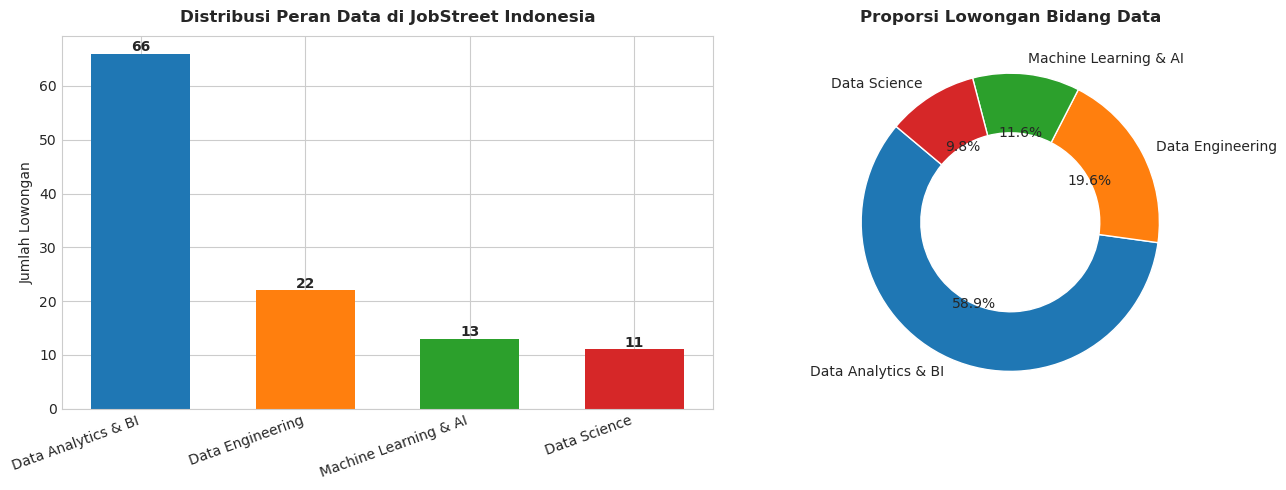

Gambar BR-01 disimpan di: jobstreet_br01_role_distribution.png


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Bar plot jumlah lowongan per grup profesi
role_counts = df_cleaned_jobs['role_group'].value_counts()
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

axes[0].bar(role_counts.index, role_counts.values, color=colors[:len(role_counts)], width=0.6)
axes[0].set_title("Distribusi Peran Data di JobStreet Indonesia", fontsize=12, fontweight='bold', pad=10)
axes[0].set_ylabel("Jumlah Lowongan", fontsize=10)
axes[0].set_xticklabels(role_counts.index, rotation=20, ha='right')
for i, v in enumerate(role_counts.values):
    axes[0].text(i, v + 0.5, str(v), ha='center', fontweight='bold', fontsize=10)

# 2. Donut plot proporsi
axes[1].pie(role_counts.values, labels=role_counts.index, autopct='%1.1f%%',
            startangle=140, colors=colors[:len(role_counts)],
            wedgeprops=dict(width=0.4, edgecolor='w'))
axes[1].set_title("Proporsi Lowongan Bidang Data", fontsize=12, fontweight='bold', pad=10)

plt.tight_layout()
fig_path = FIGURES_DIR / "jobstreet_br01_role_distribution.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Gambar BR-01 disimpan di: {fig_path.name}")

### Sel 13: EDA BR-02 – Top 15 Skill & Tools Paling Banyak Diminta

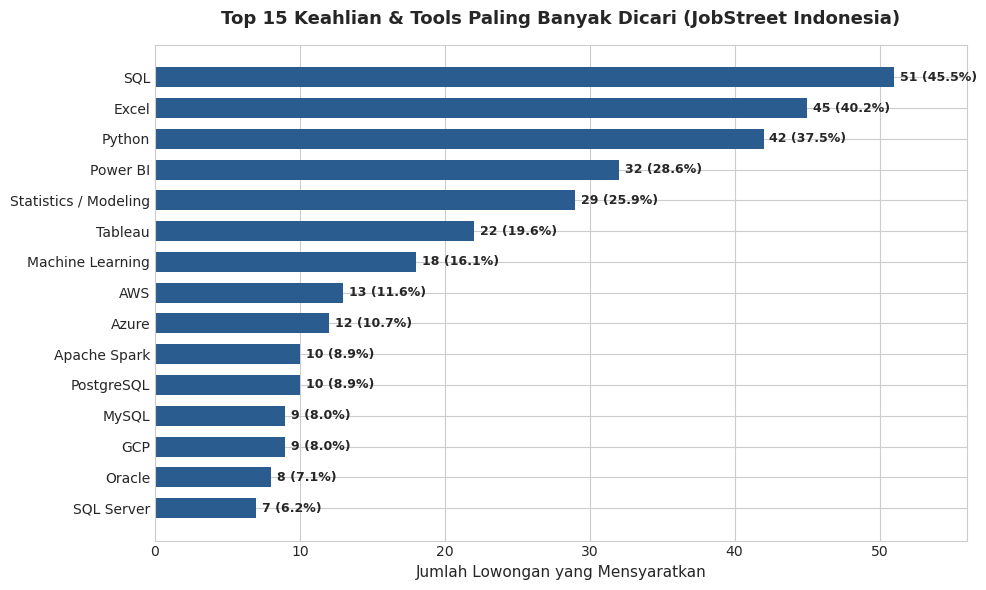

Gambar BR-02 disimpan di: jobstreet_br02_top_skills.png


In [13]:
skill_unique_counts = df_job_skills.groupby('skill_name')['job_id'].nunique().sort_values(ascending=False).head(15)
total_jobs = len(df_cleaned_jobs)
skill_pct = (skill_unique_counts / total_jobs * 100).round(1)

plt.figure(figsize=(10, 6))
bars = plt.barh(skill_unique_counts.index[::-1], skill_unique_counts.values[::-1], color='#2b5c8f', height=0.65)
plt.title("Top 15 Keahlian & Tools Paling Banyak Dicari (JobStreet Indonesia)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Jumlah Lowongan yang Mensyaratkan", fontsize=11)

for bar, pct in zip(bars, skill_pct.values[::-1]):
    plt.text(bar.get_width() + 0.4, bar.get_y() + bar.get_height()/2,
             f"{int(bar.get_width())} ({pct}%)", va='center', fontsize=9, fontweight='bold')

plt.xlim(0, max(skill_unique_counts.values) + 5)
plt.tight_layout()
fig_path = FIGURES_DIR / "jobstreet_br02_top_skills.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Gambar BR-02 disimpan di: {fig_path.name}")

### Sel 14: EDA BR-03 – Distribusi Tingkat Pengalaman Kerja (`experience_level`)

C:\Users\Victus 16\AppData\Local\Temp\ipykernel_25048\4060565267.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(exp_counts.index, rotation=25, ha='right')


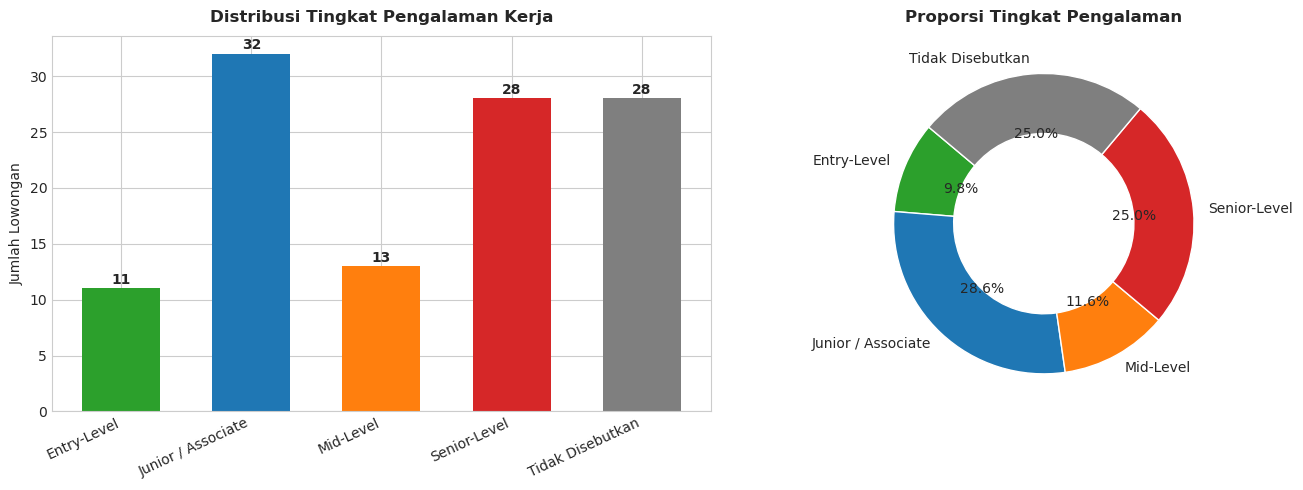

Gambar BR-03 disimpan di: jobstreet_br03_experience_level.png


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Urutan jenjang karir logis
exp_order = ['Entry-Level', 'Junior / Associate', 'Mid-Level', 'Senior-Level', 'Tidak Disebutkan']
exp_counts = df_cleaned_jobs['experience_level'].value_counts().reindex(exp_order).fillna(0)
colors_exp = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728', '#7f7f7f']

# 1. Bar Chart
axes[0].bar(exp_counts.index, exp_counts.values, color=colors_exp, width=0.6)
axes[0].set_title("Distribusi Tingkat Pengalaman Kerja", fontsize=12, fontweight='bold', pad=10)
axes[0].set_ylabel("Jumlah Lowongan", fontsize=10)
axes[0].set_xticklabels(exp_counts.index, rotation=25, ha='right')
for i, v in enumerate(exp_counts.values):
    axes[0].text(i, v + 0.4, str(int(v)), ha='center', fontweight='bold', fontsize=10)

# 2. Donut Chart
axes[1].pie(exp_counts.values, labels=exp_counts.index, autopct='%1.1f%%',
            startangle=140, colors=colors_exp,
            wedgeprops=dict(width=0.4, edgecolor='w'))
axes[1].set_title("Proporsi Tingkat Pengalaman", fontsize=12, fontweight='bold', pad=10)

plt.tight_layout()
fig_path = FIGURES_DIR / "jobstreet_br03_experience_level.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Gambar BR-03 disimpan di: {fig_path.name}")

### Sel 15: EDA BR-04 – Persyaratan Kualifikasi Pendidikan Formal

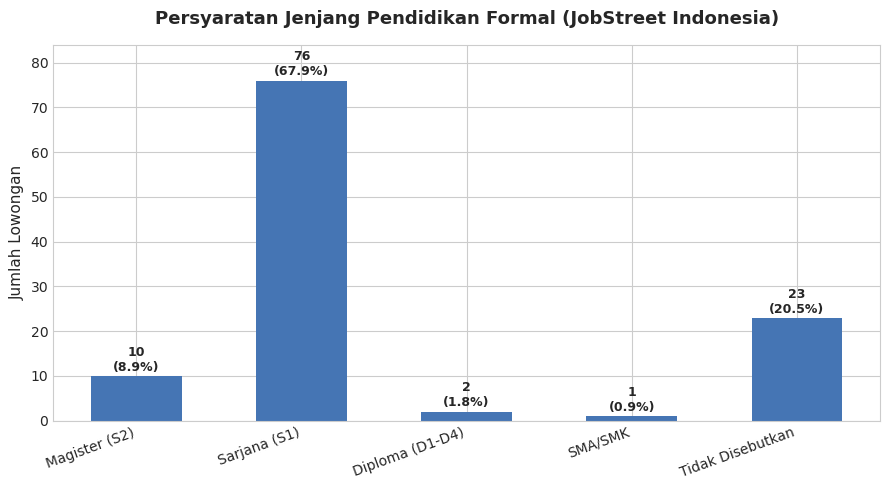

Gambar BR-04 disimpan di: jobstreet_br04_education_requirement.png


In [15]:
edu_order = ['Doktoral (S3)', 'Magister (S2)', 'Sarjana (S1)', 'Diploma (D1-D4)', 'SMA/SMK', 'Tidak Disebutkan']
edu_counts = df_cleaned_jobs['education_requirement'].value_counts().reindex(edu_order).dropna()

plt.figure(figsize=(9, 5))
bars = plt.bar(edu_counts.index, edu_counts.values, color='#4575b4', width=0.55)
plt.title("Persyaratan Jenjang Pendidikan Formal (JobStreet Indonesia)", fontsize=13, fontweight='bold', pad=15)
plt.ylabel("Jumlah Lowongan", fontsize=11)
plt.xticks(rotation=20, ha='right', fontsize=10)

for bar in bars:
    yval = bar.get_height()
    pct = (yval / len(df_cleaned_jobs) * 100)
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f"{int(yval)}\n({pct:.1f}%)",
             ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.ylim(0, max(edu_counts.values) + 8)
plt.tight_layout()
fig_path = FIGURES_DIR / "jobstreet_br04_education_requirement.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Gambar BR-04 disimpan di: {fig_path.name}")

### Sel 16: EDA BR-05 – Distribusi Gaji per Profesi Data

C:\Users\Victus 16\AppData\Local\Temp\ipykernel_25048\2263960514.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_salary, x='role_group', y='salary_median_jt', palette='Set2', width=0.45)


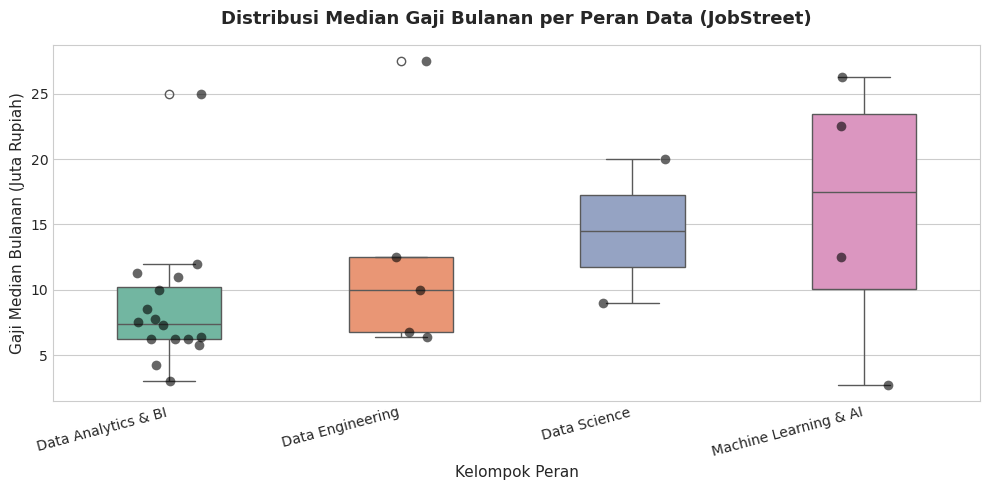

Gambar BR-05 disimpan di: jobstreet_br05_salary_distribution.png


In [16]:
df_salary = df_cleaned_jobs.dropna(subset=['salary_median']).copy()

if len(df_salary) > 0:
    plt.figure(figsize=(10, 5))
    
    # Konversi ke jutaan rupiah
    df_salary['salary_median_jt'] = df_salary['salary_median'] / 1e6
    
    sns.boxplot(data=df_salary, x='role_group', y='salary_median_jt', palette='Set2', width=0.45)
    sns.stripplot(data=df_salary, x='role_group', y='salary_median_jt', color='black', alpha=0.6, size=7, jitter=0.15)
    
    plt.title("Distribusi Median Gaji Bulanan per Peran Data (JobStreet)", fontsize=13, fontweight='bold', pad=15)
    plt.ylabel("Gaji Median Bulanan (Juta Rupiah)", fontsize=11)
    plt.xlabel("Kelompok Peran", fontsize=11)
    plt.xticks(rotation=15, ha='right')
    
    plt.tight_layout()
    fig_path = FIGURES_DIR / "jobstreet_br05_salary_distribution.png"
    plt.savefig(fig_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Gambar BR-05 disimpan di: {fig_path.name}")
else:
    print("Catatan: Tidak ada lowongan dengan informasi gaji terbuka pada sampel ini.")

### Sel 17: EDA BR-06 – Distribusi Geografis dan Fleksibilitas Mode Kerja

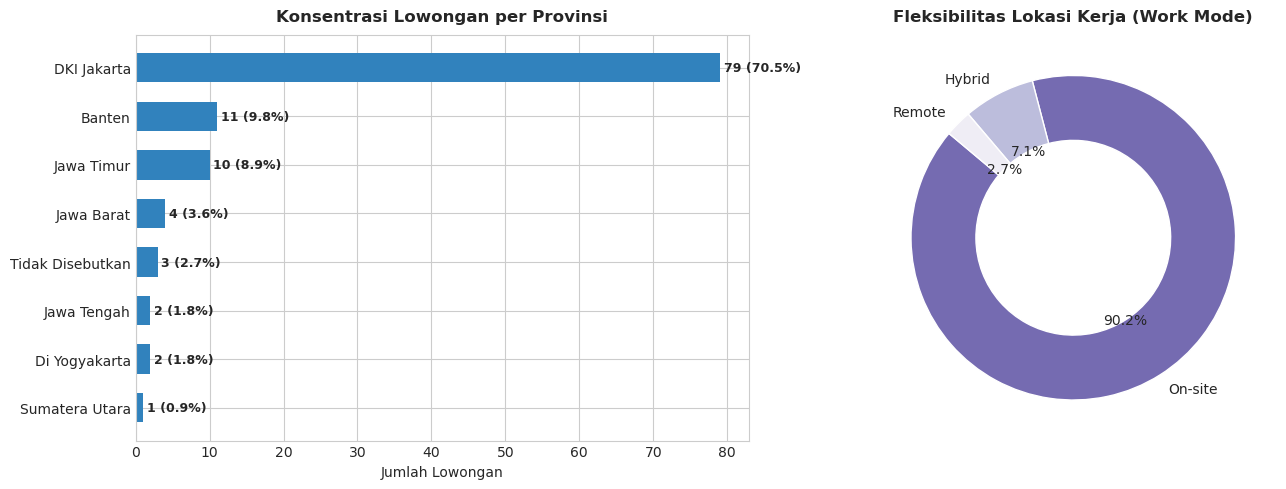

Gambar BR-06 disimpan di: jobstreet_br06_geo_and_mode.png


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Distribusi per Provinsi
prov_counts = df_cleaned_jobs['province'].value_counts()
axes[0].barh(prov_counts.index[::-1], prov_counts.values[::-1], color='#3182bd', height=0.6)
axes[0].set_title("Konsentrasi Lowongan per Provinsi", fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel("Jumlah Lowongan", fontsize=10)
for i, v in enumerate(prov_counts.values[::-1]):
    axes[0].text(v + 0.5, i, f"{v} ({v/len(df_cleaned_jobs)*100:.1f}%)", va='center', fontweight='bold', fontsize=9)

# 2. Mode Kerja (Work Mode)
mode_counts = df_cleaned_jobs['work_mode'].value_counts()
mode_colors = ['#756bb1', '#bcbddc', '#efedf5']
axes[1].pie(mode_counts.values, labels=mode_counts.index, autopct='%1.1f%%',
            startangle=140, colors=mode_colors[:len(mode_counts)],
            wedgeprops=dict(width=0.4, edgecolor='w'))
axes[1].set_title("Fleksibilitas Lokasi Kerja (Work Mode)", fontsize=12, fontweight='bold', pad=10)

plt.tight_layout()
fig_path = FIGURES_DIR / "jobstreet_br06_geo_and_mode.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Gambar BR-06 disimpan di: {fig_path.name}")

### Sel 18: Analisis Transparansi Atribut & Nilai Tidak Disebutkan (*Transparency Metric*)

=== MATRIKS TRANSPARANSI INFORMASI LOWONGAN KERJA (JOBSTREET) ===


,Fitur,Terbuka / Disebutkan,Tidak Disebutkan,Persentase Terbuka (%)
0,salary_median,27,85,24.1
1,experience_level,84,28,75.0
2,education_requirement,89,23,79.5
3,city,110,2,98.2
4,province,109,3,97.3
5,work_mode,112,0,100.0


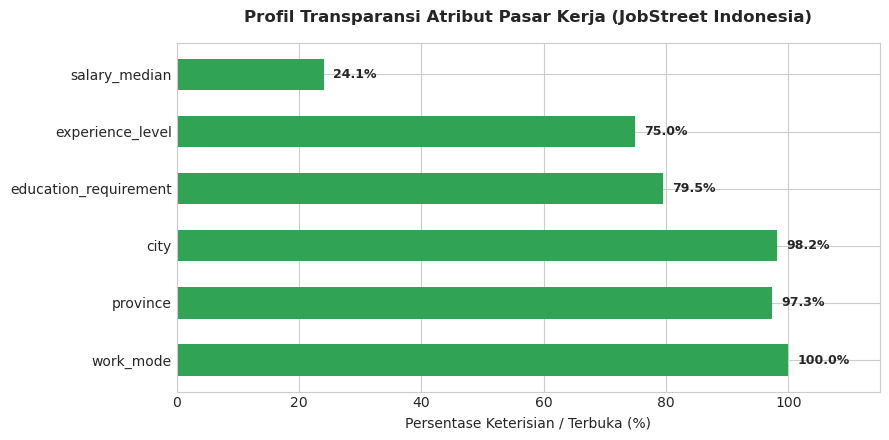

Gambar transparansi disimpan di: jobstreet_attribute_transparency_profile.png


In [18]:
# Hitung persentase keterisian vs Tidak Disebutkan
features_to_audit = ['salary_median', 'experience_level', 'education_requirement', 'city', 'province', 'work_mode']

transparency_data = []
for feat in features_to_audit:
    if feat == 'salary_median':
        disclosed = df_cleaned_jobs[feat].notna().sum()
    else:
        disclosed = (df_cleaned_jobs[feat] != 'Tidak Disebutkan').sum()
        
    undisclosed = len(df_cleaned_jobs) - disclosed
    transparency_data.append({
        'Fitur': feat,
        'Terbuka / Disebutkan': disclosed,
        'Tidak Disebutkan': undisclosed,
        'Persentase Terbuka (%)': round(disclosed / len(df_cleaned_jobs) * 100, 1)
    })

df_transparency = pd.DataFrame(transparency_data)
print("=== MATRIKS TRANSPARANSI INFORMASI LOWONGAN KERJA (JOBSTREET) ===")
display(df_transparency)

# Visualisasi Tingkat Keterisian
plt.figure(figsize=(9, 4.5))
y_pos = range(len(df_transparency))
bars = plt.barh(df_transparency['Fitur'][::-1], df_transparency['Persentase Terbuka (%)'][::-1], color='#31a354', height=0.55)
plt.title("Profil Transparansi Atribut Pasar Kerja (JobStreet Indonesia)", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Persentase Keterisian / Terbuka (%)", fontsize=10)
plt.xlim(0, 115)

for bar in bars:
    val = bar.get_width()
    plt.text(val + 1.5, bar.get_y() + bar.get_height()/2, f"{val:.1f}%", va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
fig_path = FIGURES_DIR / "jobstreet_attribute_transparency_profile.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Gambar transparansi disimpan di: {fig_path.name}")

### Sel 19: Ekspor Dataset Bersih (Processed Layer)

In [19]:
cleaned_jobs_path = PROCESSED_DATA_DIR / "cleaned_jobs_jobstreet.csv"
job_skills_path = PROCESSED_DATA_DIR / "job_skills_jobstreet.csv"

df_cleaned_jobs.to_csv(cleaned_jobs_path, index=False, encoding="utf-8")
df_job_skills.to_csv(job_skills_path, index=False, encoding="utf-8")

print("Dataset bersih berhasil diekspor:")
print(f"1. Cleaned Jobs : {cleaned_jobs_path.resolve()} ({len(df_cleaned_jobs)} baris, {cleaned_jobs_path.stat().st_size / 1024:.1f} KB)")
print(f"2. Job Skills   : {job_skills_path.resolve()} ({len(df_job_skills)} relasi, {job_skills_path.stat().st_size / 1024:.1f} KB)")

Dataset bersih berhasil diekspor:
1. Cleaned Jobs : C:\Users\Victus 16\data-project\analisi_loker_data_indonesia\data\processed\cleaned_jobs_jobstreet.csv (112 baris, 31.9 KB)
2. Job Skills   : C:\Users\Victus 16\data-project\analisi_loker_data_indonesia\data\processed\job_skills_jobstreet.csv (426 relasi, 16.1 KB)
